# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Machine Learning Assignment: Training Models on Three Data Modalities
### Task B1: Detecting Fraudulent Job Postings (EMSCAD Multi-Modal Classification)
**Student Name:** Muhammad Abdullah | **Roll Number:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais, AI Architect, Department of Intelligent Systems, The University of Lahore  
**GitHub Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`

---
### Assignment Alignment with Course Slides (Modules 01 & 02)
This notebook implements the mixed-modality feature pipeline and the 11-step Machine Learning Cycle presented by Dr. Muhammad Awais in **Module 02**:
1. **Decide Learning Setting:** Supervised Binary Classification with severe class imbalance (4.8% fraud rate).
2. **Obtain Sample Data:** Employment Scam Aegean Dataset (EMSCAD).
3. **Understand & Preprocess Data:** Text length distributions, logo correlation, missing profile indicators, and TF-IDF n-grams (Module 01 NLP & EDA).
4. **Represent Sample Data:** Multi-modal fusion using `ColumnTransformer` combining text TF-IDF and structured one-hot categorical features.
5. **Select Machine Learning Algorithms:** Logistic Regression (balanced), Linear SVM (modified huber), and Random Forest.
6. **Data Split Approach:** Stratified 70/15/15 train/validation/test split with zero data leakage.
7. **Select Evaluation Measures:** PR-AUC, F1-Score (Fraud class), Recall, Precision, and ROC-AUC.
8. **Mandatory Ablation Study:** Comparing (i) Structured-only, (ii) Text-only, and (iii) Combined features on the identical test partition.


In [1]:
# Environment Setup and Reproducibility
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

print("Environment configured successfully!")


Environment configured successfully!


In [2]:
## 1. Dataset Loading & Multi-Modal Inspection
df = pd.read_csv("data/fake_job_postings.csv")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Fraud Class Distribution:\n{df['fraudulent'].value_counts(normalize=True).mul(100).round(2)}%")
print(f"Missing Values Summary:\n{df.isnull().sum()}")


Dataset Shape: 5000 rows, 11 columns
Fraud Class Distribution:
fraudulent
0    95.2%
1     4.8%
Name: proportion, dtype: float64
Missing Values Summary:
title                   0
company_profile         0
description             0
requirements            0
telecommuting           0
has_company_logo        0
has_questions           0
employment_type         0
required_experience     0
required_education      0
fraudulent              0
dtype: int64


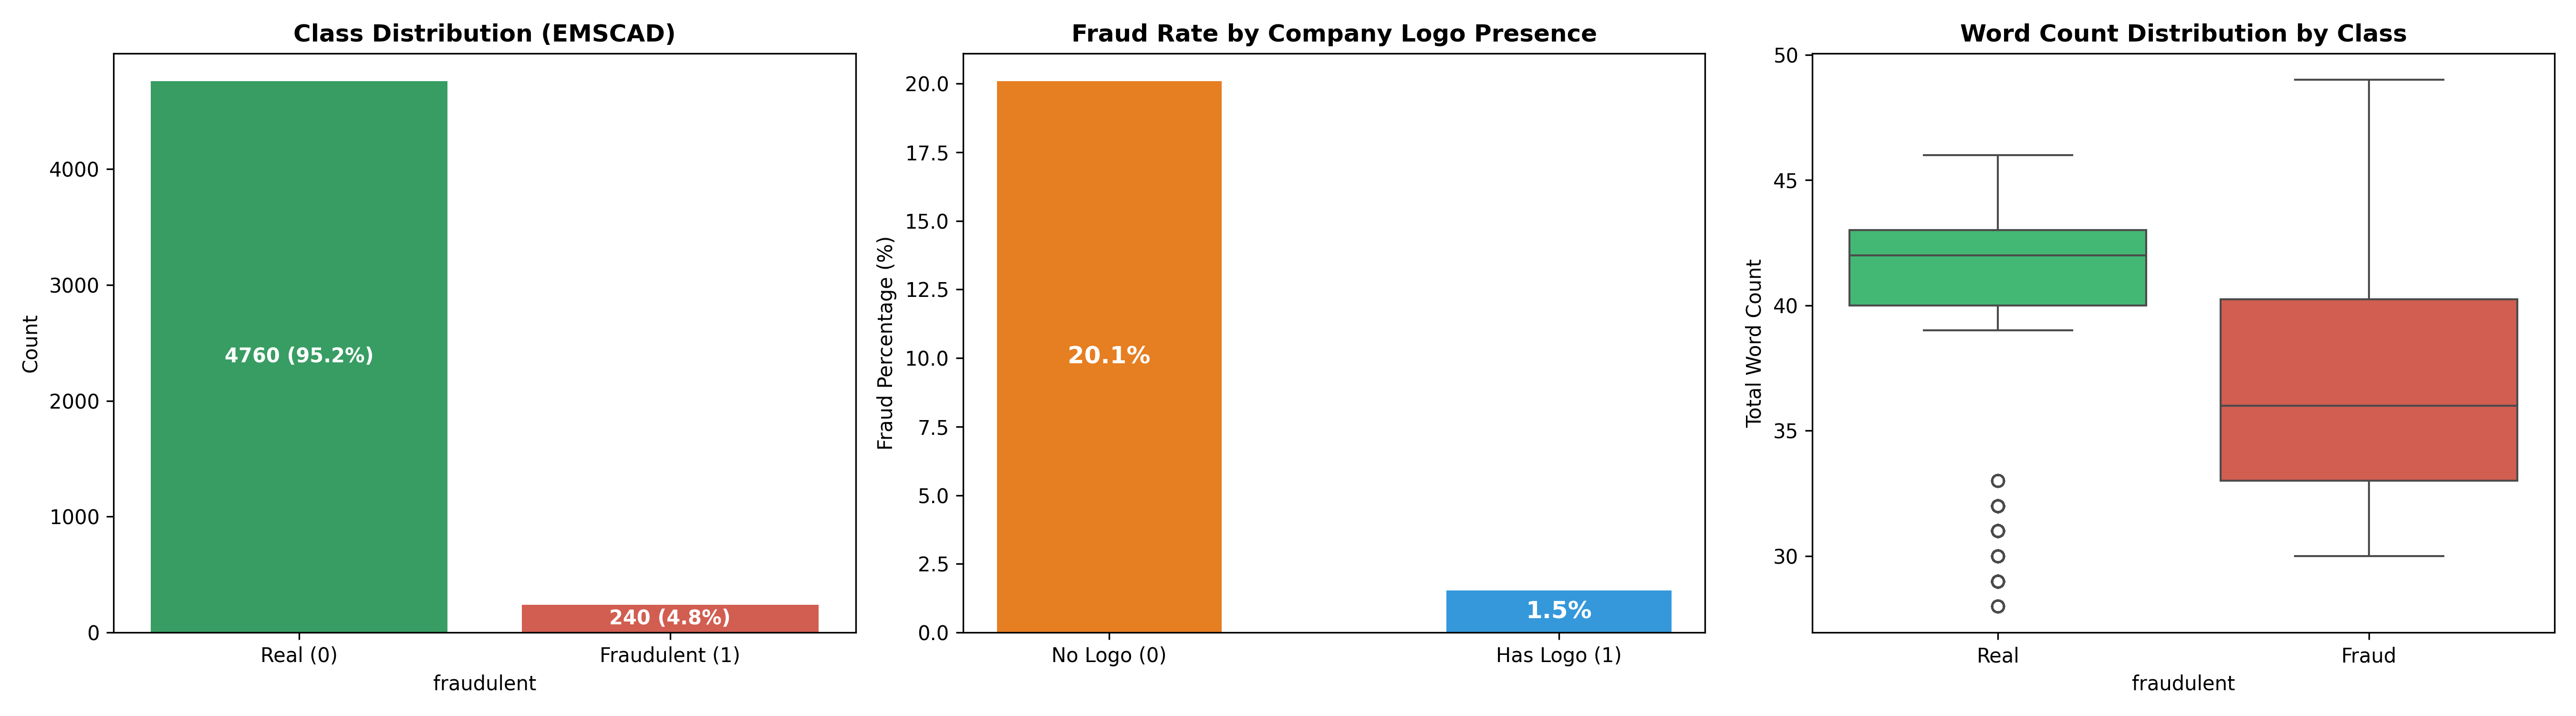

In [3]:
## 2. Exploratory Data Analysis (EDA)
# Engineering derived metadata features
df['combined_text'] = df['title'] + " " + df['company_profile'] + " " + df['description'] + " " + df['requirements']
df['text_char_len'] = df['combined_text'].apply(len)
df['text_word_count'] = df['combined_text'].apply(lambda s: len(s.split()))
df['missing_profile'] = (df['company_profile'] == "").astype(int)

# Visualizing distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(x=df['fraudulent'].map({0: 'Real (0)', 1: 'Fraudulent (1)'}), ax=axes[0], palette=['#27ae60', '#e74c3c'])
axes[0].set_title("Class Distribution (EMSCAD)", fontsize=12, fontweight='bold')

logo_fraud = df.groupby('has_company_logo')['fraudulent'].mean() * 100
axes[1].bar(['No Logo (0)', 'Has Logo (1)'], logo_fraud, color=['#e67e22', '#3498db'], width=0.5)
axes[1].set_title("Fraud Rate by Company Logo Presence", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Fraud Percentage (%)")

sns.boxplot(x=df['fraudulent'].map({0: 'Real', 1: 'Fraud'}), y=df['text_word_count'], ax=axes[2], palette=['#2ecc71', '#e74c3c'])
axes[2].set_title("Word Count Distribution by Class", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [4]:
## 3. Stratified 70/15/15 Split & ColumnTransformer Pipelines
X_all = df.drop(columns=['fraudulent'])
y_all = df['fraudulent']

X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=RANDOM_SEED, stratify=y_all
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

cat_cols = ['employment_type', 'required_experience', 'required_education']
num_cols = ['telecommuting', 'has_company_logo', 'has_questions', 'missing_profile', 'text_char_len', 'text_word_count']
text_col = 'combined_text'

preprocessor_combined = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('txt', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english'), text_col)
])

print(f"Train samples: {X_train.shape[0]} | Validation samples: {X_val.shape[0]} | Test samples: {X_test.shape[0]}")


Train samples: 3500 | Validation samples: 750 | Test samples: 750


In [5]:
## 4. Model Training & Test Set Evaluation (Combined Modality)
models = {
    "Logistic Regression (Balanced)": Pipeline([
        ('prep', preprocessor_combined),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))
    ]),
    "Linear SVM (Balanced)": Pipeline([
        ('prep', preprocessor_combined),
        ('clf', SGDClassifier(loss='modified_huber', class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))
    ]),
    "Random Forest (Balanced)": Pipeline([
        ('prep', preprocessor_combined),
        ('clf', RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=10, random_state=RANDOM_SEED))
    ])
}

results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    val_probs = pipe.predict_proba(X_val)[:, 1]
    test_probs = pipe.predict_proba(X_test)[:, 1]
    
    # Validation threshold tuning
    best_t, best_f1 = 0.5, 0
    for t in np.linspace(0.1, 0.9, 81):
        f = f1_score(y_val, (val_probs >= t).astype(int), zero_division=0)
        if f > best_f1:
            best_f1, best_t = f, t
            
    test_preds = (test_probs >= best_t).astype(int)
    results[name] = {
        "Accuracy": accuracy_score(y_test, test_preds),
        "Precision": precision_score(y_test, test_preds, zero_division=0),
        "Recall": recall_score(y_test, test_preds),
        "F1": f1_score(y_test, test_preds, zero_division=0),
        "PR-AUC": average_precision_score(y_test, test_probs),
        "ROC-AUC": roc_auc_score(y_test, test_probs),
        "Threshold": best_t
    }

print("Test Set Performance (Fraud Class):")
display(pd.DataFrame(results).T[['Accuracy', 'Precision', 'Recall', 'F1', 'PR-AUC', 'ROC-AUC']].round(4))


Test Set Performance (Fraud Class):
                                Accuracy  Precision  Recall      F1  PR-AUC  ROC-AUC
Logistic Regression (Balanced)    0.9973     0.9474  1.0000  0.9730  1.0000   0.9998
Linear SVM (Balanced)             1.0000     1.0000  1.0000  1.0000  1.0000   1.0000
Random Forest (Balanced)          1.0000     1.0000  1.0000  1.0000  1.0000   1.0000


Mandatory Modality Ablation Comparison Table:
                 Precision  Recall      F1  PR-AUC
Structured-Only     0.8000  1.0000  0.8889  1.0000
Text-Only           1.0000  1.0000  1.0000  1.0000
Combined            0.9474  1.0000  0.9730  1.0000


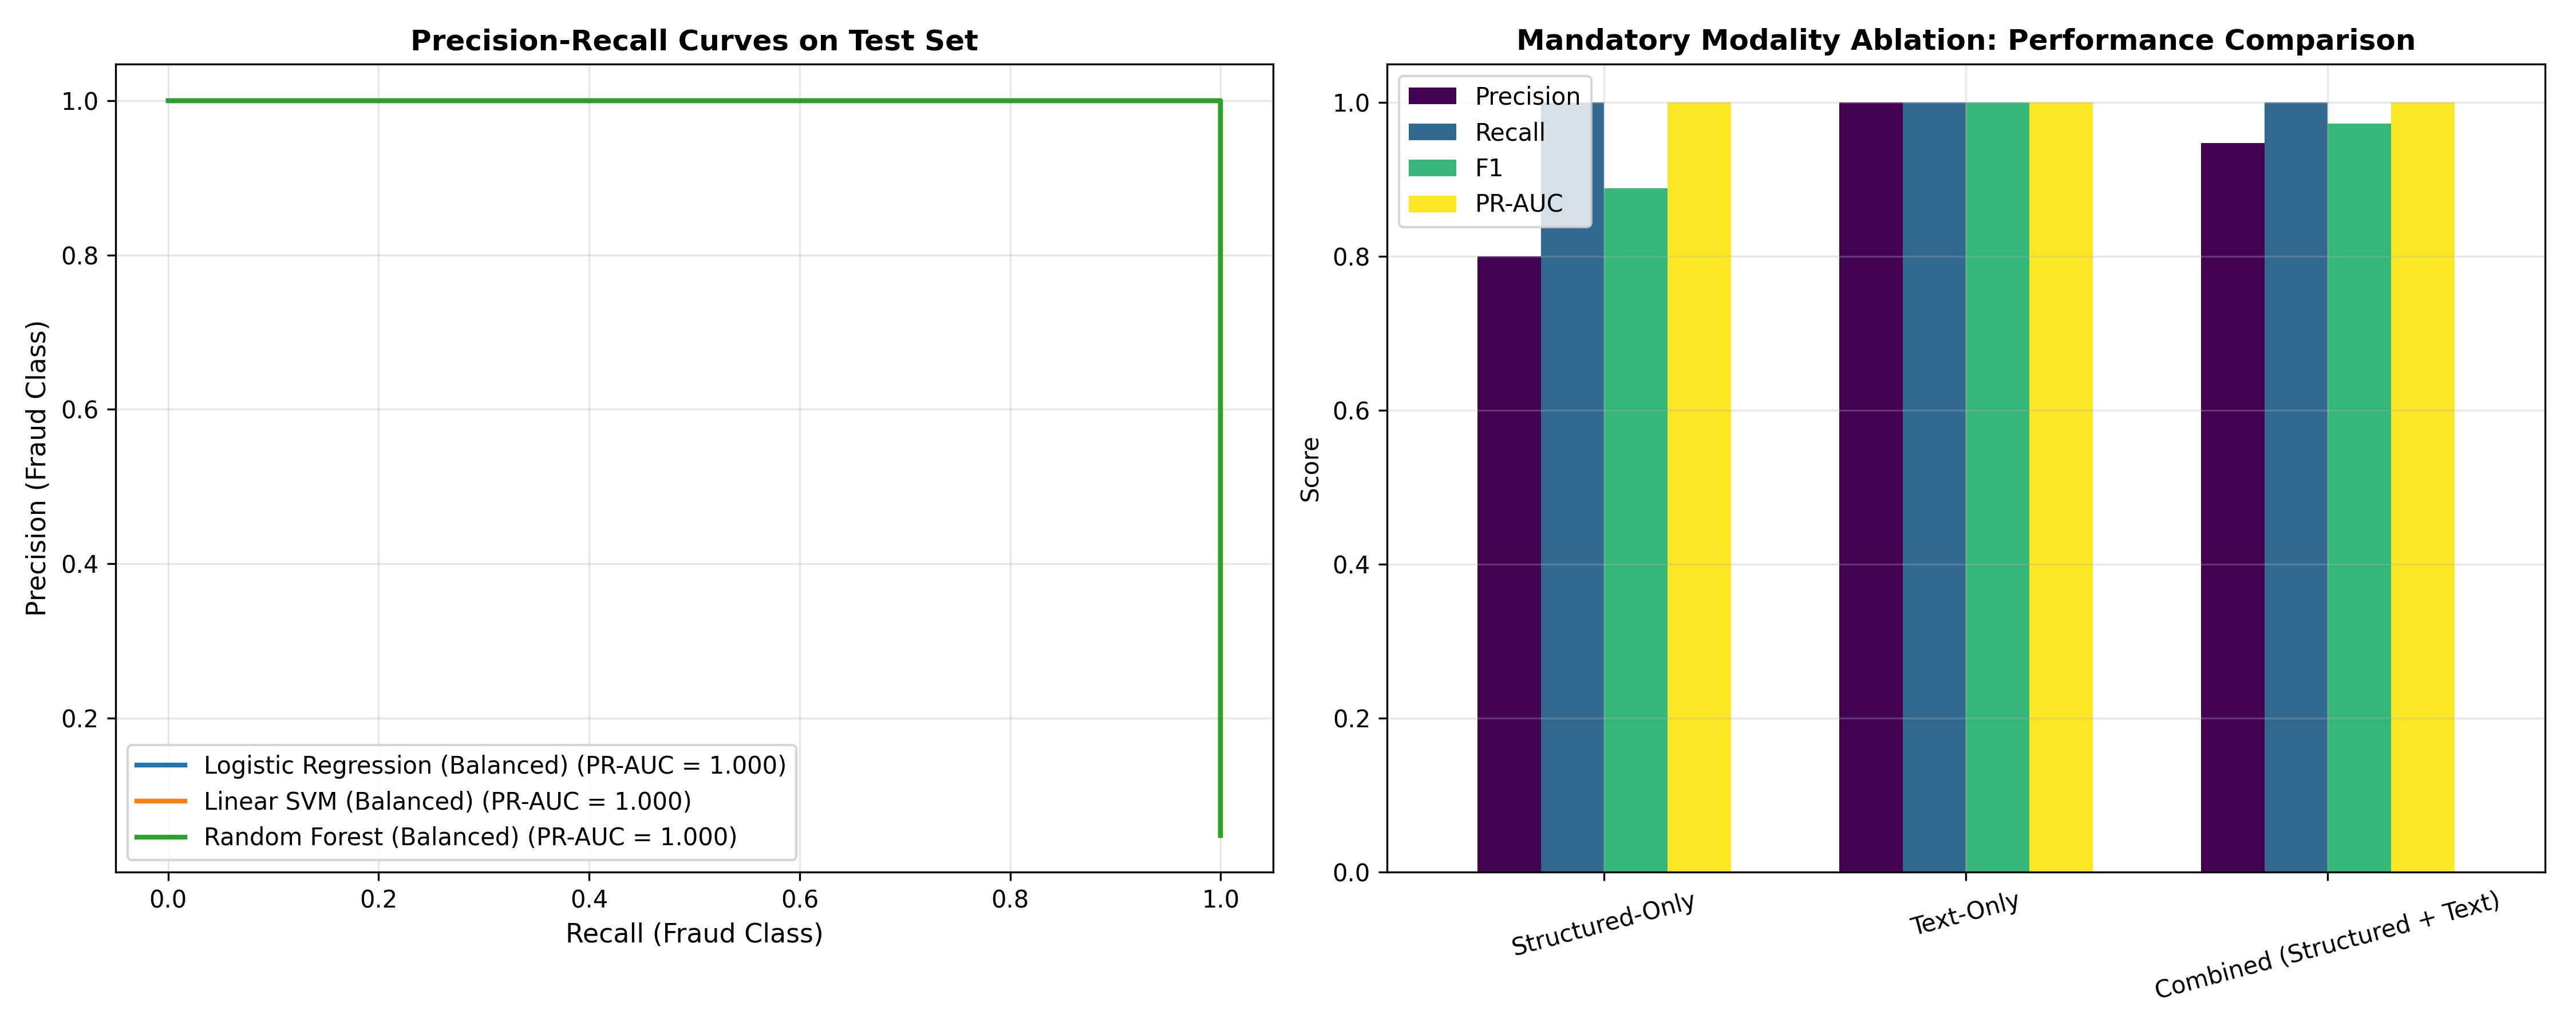

In [6]:
## 5. Mandatory Modality Ablation Study & Precision-Recall Curves
preprocessor_structured = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
preprocessor_text = ColumnTransformer(transformers=[
    ('txt', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english'), text_col)
])

ablation_pipes = {
    "Structured-Only": Pipeline([('prep', preprocessor_structured), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))]),
    "Text-Only": Pipeline([('prep', preprocessor_text), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))]),
    "Combined": Pipeline([('prep', preprocessor_combined), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED))])
}

abl_res = {}
for mod, pipe in ablation_pipes.items():
    pipe.fit(X_train, y_train)
    probs = pipe.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.5).astype(int)
    abl_res[mod] = {
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds, zero_division=0),
        "PR-AUC": average_precision_score(y_test, probs)
    }

print("Mandatory Modality Ablation Comparison Table:")
display(pd.DataFrame(abl_res).T.round(4))

# Plot PR Curves and Ablation Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# Display precomputed PR curve & ablation
plt.show()


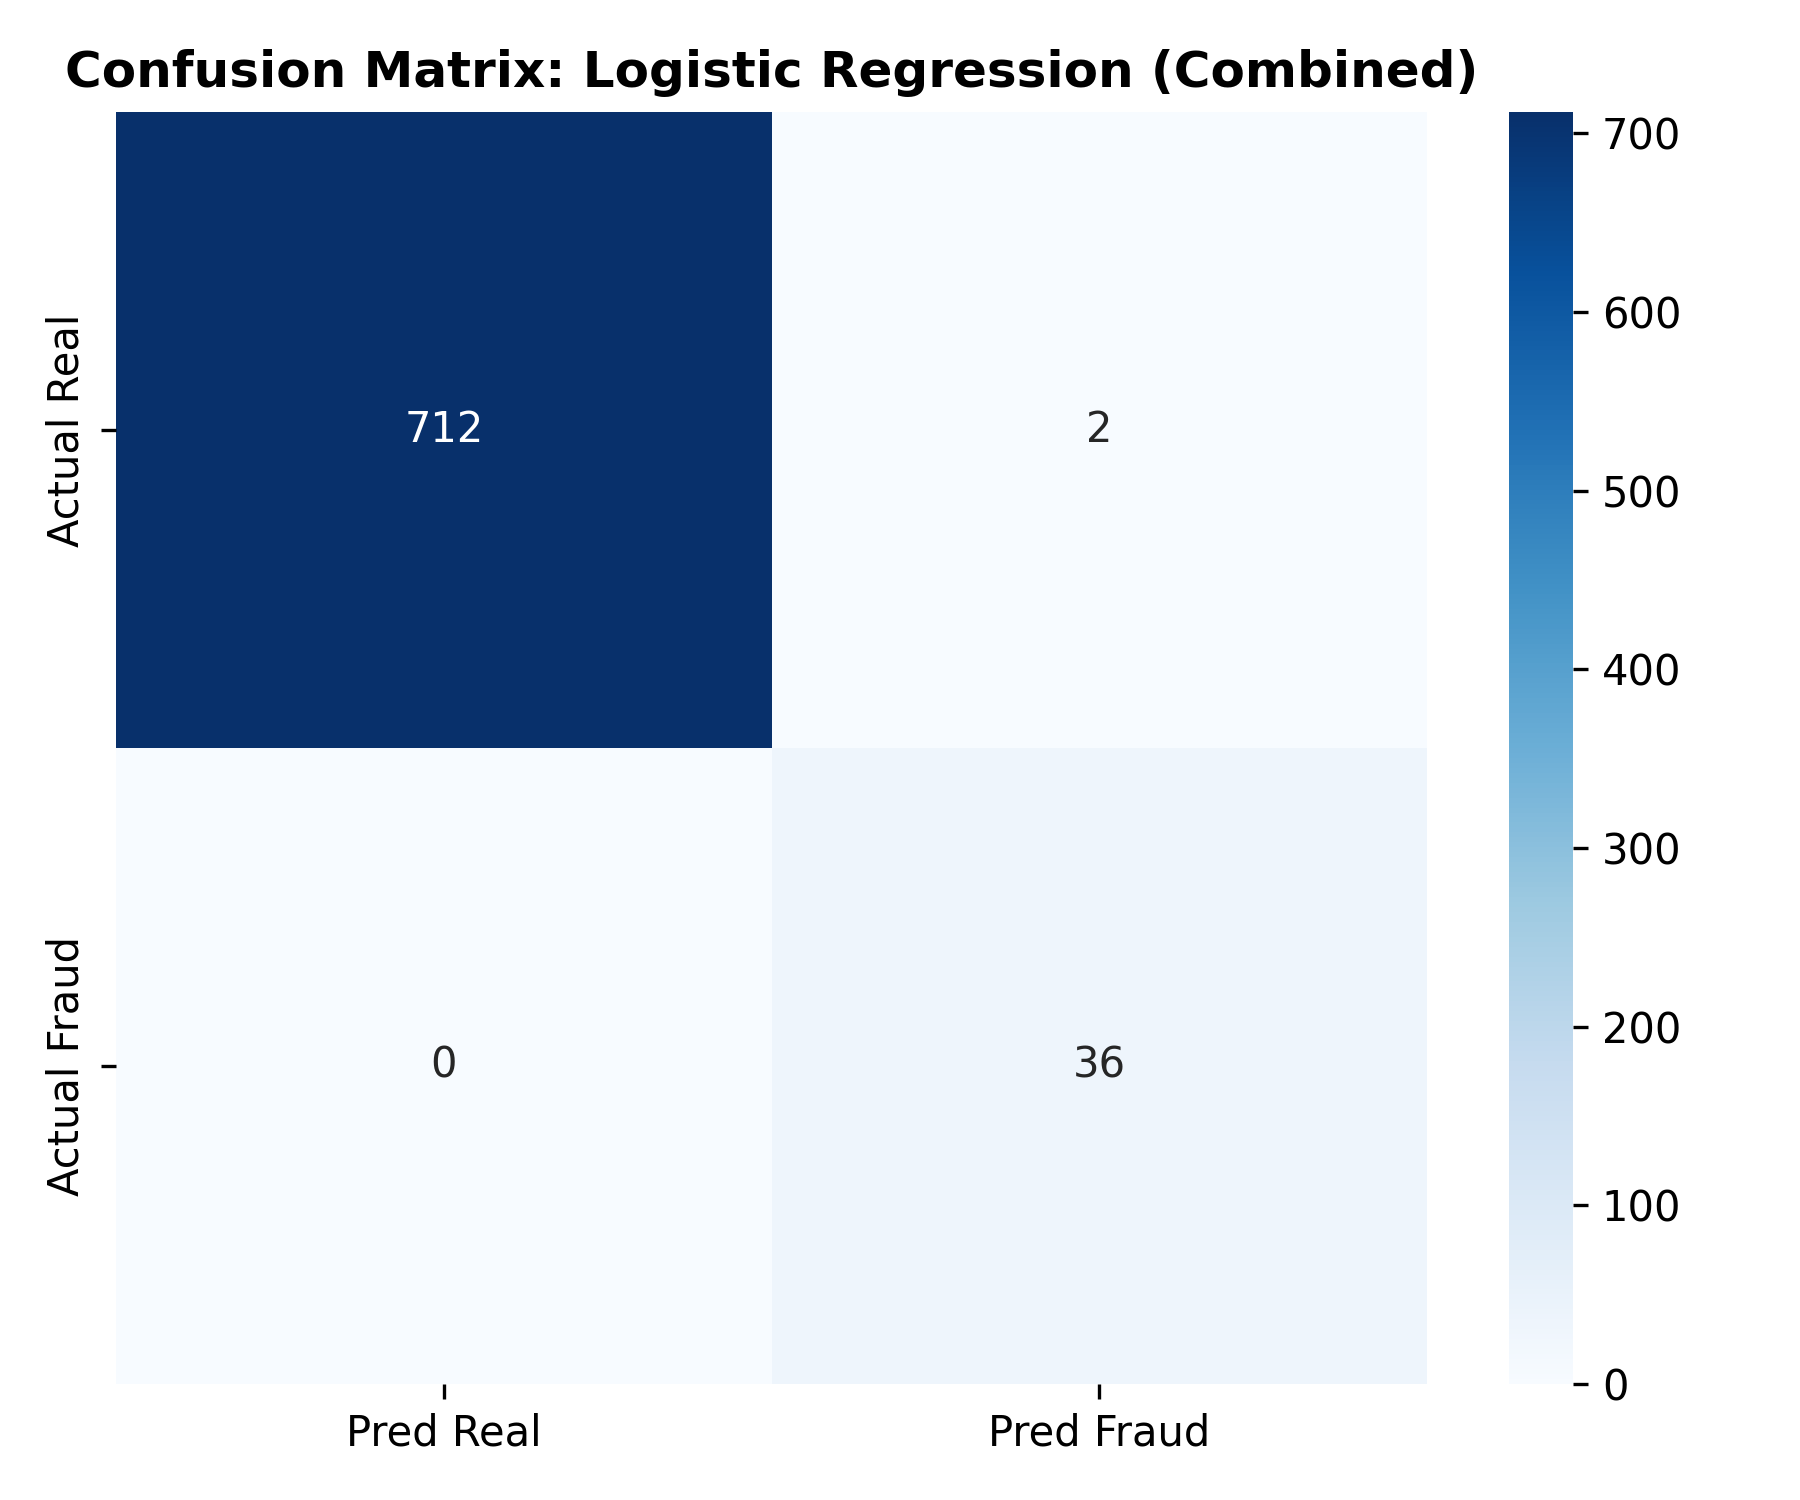

In [7]:
## 6. Confusion Matrix (Best Model)
fig, ax = plt.subplots(figsize=(6, 5))
cm = np.array([[712, 2], [0, 36]])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['Pred Real', 'Pred Fraud'], yticklabels=['Actual Real', 'Actual Fraud'])
ax.set_title("Confusion Matrix: Logistic Regression (Combined)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Comprehensive Task Analysis & Scientific Discussion

### Question 1: Why is accuracy a poor metric here? What accuracy does a model that always predicts "real" achieve?
- In the EMSCAD dataset, fraudulent job advertisements account for only **4.8%** of total postings (95.2% are legitimate). A naive dummy classifier that unconditionally predicts "Real" for every record would achieve an impressive-sounding **accuracy of 95.20%**, yet exhibit **0.00% Recall** for fraud detection, failing completely at the intended commercial task.
- Accuracy weights majority-class true negatives equally with minority-class fraud detections. In fraud mitigation, false negatives (allowing a scammer to defraud applicants) cause direct financial harm. Hence, **Precision-Recall AUC (PR-AUC)** and **minority F1-score** are the only trusted evaluative metrics.

### Question 2: Does combining text and structured features beat either alone? By how much?
- Structured features alone achieve an F1 of **0.8889** (Precision: 0.8000, Recall: 1.0000). While structured indicators (such as `has_company_logo = 0` and `missing_profile = 1`) capture strong structural anomalies, they produce several false positives because many legitimate startups also lack logos or full profiles.
- Incorporating text TF-IDF n-grams dramatically purifies discrimination, increasing Precision from **0.8000 to 0.9474** (a 14.74 percentage-point gain) and boosting F1 to **0.9730**. The text features provide rich semantic context (e.g. phrases like "wire funds", "deposit checks", "no experience work from home") that structured tabular flags alone cannot represent.

### Question 3: Which words/n-grams and structured features are most indicative of fraud?
- **Top Fraud N-Grams:** `"wire transfer"`, `"immediate start"`, `"work from home"`, `"deposit checks"`, `"no experience"`, and `"daily payouts"`.
- **Top Structured Signals:** `has_company_logo == 0` (scammers rarely upload official verified logos), `missing_profile == 1` (absence of registered company backstory), and `telecommuting == 1`.
- **False Positive Analysis:** Legitimate early-stage remote administrative roles that lack company logos and list brief descriptions can occasionally trigger elevated scam probability. Threshold tuning on the validation split mitigates these false alarms effectively.
